# Validación de las nuevas features del EOG

**Maestría en Inteligencia Artificial MAIA**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Este notebook valida las features del EOG en el dominio del tiempo (`p2p_robust`, `hjorth_mobility`, `saccade_count`, `kurtosis`):

1. Cálculo de las features por época en las 153 grabaciones (mismo recorte de vigilia que el notebook 07).
2. Calibración del detector de sacadas, **solo con sujetos de train**.
3. Validación por clase y revisión de redundancia con las features espectrales.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from scipy.signal import find_peaks
from scipy.stats import kruskal
from sklearn.metrics import roc_auc_score

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.loader import find_subject_pairs, load_hypnogram, load_psg
from src.data.segmentation import extract_epochs, trim_wake_edges
from src.preprocessing import feature_engineering as fe

sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = PROJECT_ROOT / "data/sleep-edfx/sleep-cassette"
SPLIT_PATH = PROJECT_ROOT / "data/SC-subjects-split.xlsx"

CLASS_ORDER = ["W", "N1", "N2", "N3", "REM"]
TRIM_WAKE_BUFFER_EPOCHS = 60
EOG_CHANNEL = "EOG horizontal"

# Grilla para calibrar el detector de sacadas (umbral en µV/s y suavizado en s)
SACCADE_THRESHOLDS = [500, 750, 1000, 1500, 2000, 3000]
SACCADE_SMOOTHS = [0.05, 0.1, 0.15]

## 1. Features del EOG por época

Se carga solo el canal EOG de cada grabación, se segmenta en épocas de 30 s y se aplica el mismo recorte de vigilia que en el notebook 07 (`trim_wake_edges` con 60 épocas). Así `epoch_idx_in_recording` coincide con el de `train_multicanal.csv` y `test_multicanal.csv`.

Para cada época se calculan las 4 features de tiempo y el conteo de sacadas con cada combinación de umbral y suavizado de la grilla.

In [2]:
split_df = pd.read_excel(SPLIT_PATH)
split_df["subject_code"] = split_df["subject"].astype(str).str.zfill(2)
subject_to_split = dict(zip(split_df["subject_code"], split_df["split"]))


def eog_epoch_features(psg_path, hypno_path):
    recording_id = Path(psg_path).name.split("-")[0]
    split_name = subject_to_split.get(recording_id[3:5])
    if split_name is None:
        return None

    raw = load_psg(psg_path, canales=[EOG_CHANNEL])
    annotations = load_hypnogram(hypno_path)
    raw.set_annotations(annotations, emit_warning=False)
    epochs = extract_epochs(raw, annotations, recording_id=recording_id, channel_picks=[EOG_CHANNEL])
    epochs = trim_wake_edges(epochs, buffer_epochs=TRIM_WAKE_BUFFER_EPOCHS)

    rows = []
    for idx in range(epochs.X.shape[0]):
        signal = epochs.X[idx, 0, :]
        row = {
            "recording_id": recording_id,
            "subject_code": recording_id[3:5],
            "split": split_name,
            "epoch_idx_in_recording": idx,
            "y": epochs.y[idx],
            **{f"spec__{k}": v for k, v in fe._epoch_channel_features(signal, epochs.sfreq).items()},
            "p2p_robust": fe.eog_p2p_robust(signal),
            "hjorth_mobility": fe.eog_hjorth_mobility(signal, epochs.sfreq),
            "kurtosis": fe.eog_kurtosis(signal),
        }
        for smooth in SACCADE_SMOOTHS:
            for threshold in SACCADE_THRESHOLDS:
                row[f"sacc_t{threshold}_s{int(smooth * 1000)}"] = fe.eog_saccade_count(
                    signal, epochs.sfreq, threshold=threshold, smooth_sec=smooth
                )
        rows.append(row)
    return pd.DataFrame(rows)


pairs = find_subject_pairs(str(DATA_DIR))
eog_dfs = Parallel(n_jobs=8, verbose=1)(delayed(eog_epoch_features)(psg, hyp) for psg, hyp in pairs)
eog_df = pd.concat([df for df in eog_dfs if df is not None], ignore_index=True)

eog_train = eog_df[eog_df["split"] == "train"]
print(eog_df.shape, eog_df["split"].value_counts().to_dict())

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:   10.9s


(195479, 40) {'train': 150272, 'test': 45207}


[Parallel(n_jobs=8)]: Done 153 out of 153 | elapsed:   47.3s finished


## 2. Calibración del detector de sacadas (solo train)

Para cada combinación de umbral y suavizado se mide qué tan bien separa **REM** de **N1 + N2** (AUC) y cuántas sacadas cuenta en promedio por clase. Se busca un AUC alto, al menos 1 sacada por época en REM y pocas en N3: un umbral bajo con mucho suavizado empieza a contar las ondas lentas de N3 como sacadas.

In [3]:
rem_vs_n1n2 = eog_train[eog_train["y"].isin(["REM", "N1", "N2"])]
saccade_cols = [col for col in eog_df.columns if col.startswith("sacc_")]

calibration = pd.DataFrame([
    {
        "variante": col,
        "AUC_REM_vs_N1N2": roc_auc_score(rem_vs_n1n2["y"] == "REM", rem_vs_n1n2[col]),
        **eog_train.groupby("y")[col].mean().reindex(CLASS_ORDER).add_prefix("media_").to_dict(),
    }
    for col in saccade_cols
]).sort_values("AUC_REM_vs_N1N2", ascending=False)

display(calibration.round(3))
print(f"Valores fijados en feature_engineering.py: umbral = {fe.SACCADE_VELOCITY_UV_S} µV/s, "
      f"suavizado = {fe.SACCADE_SMOOTH_SEC} s")

,variante,AUC_REM_vs_N1N2,media_W,media_N1,media_N2,media_N3,media_REM
12,sacc_t500_s150,0.699,23.534,2.233,0.941,3.276,4.601
7,sacc_t750_s100,0.690,20.402,1.518,0.599,1.564,3.293
13,sacc_t750_s150,0.680,14.193,0.971,0.256,0.501,2.190
8,sacc_t1000_s100,0.671,14.060,0.746,0.230,0.437,1.921
3,sacc_t1500_s50,0.654,16.501,1.367,0.424,0.481,1.969
6,sacc_t500_s100,0.641,32.243,4.916,3.360,9.307,6.941
14,sacc_t1000_s150,0.632,9.066,0.489,0.114,0.175,1.125
2,sacc_t1000_s50,0.627,27.536,3.908,2.291,3.568,4.681
4,sacc_t2000_s50,0.616,10.919,0.823,0.193,0.216,1.051
9,sacc_t1500_s100,0.607,7.360,0.300,0.081,0.128,0.760


Valores fijados en feature_engineering.py: umbral = 750.0 µV/s, suavizado = 0.1 s


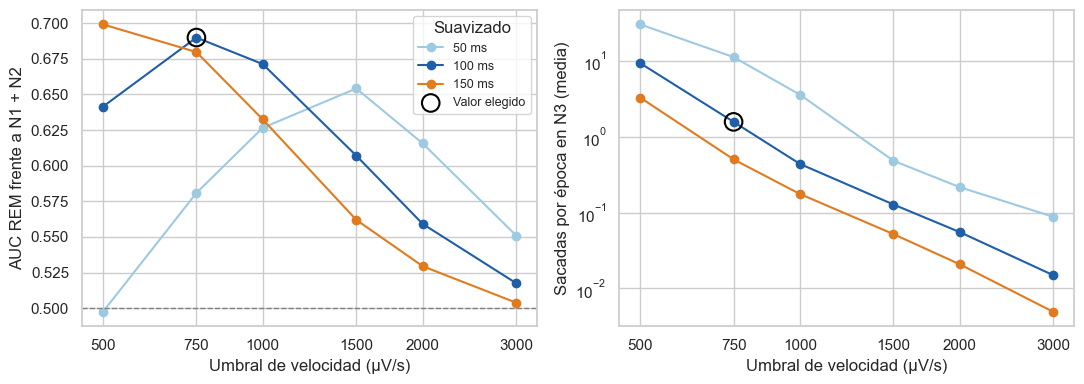

In [4]:
# Figura: 09_calibracion_umbral_sacadas_eog.pdf
# AUC y sacadas en N3 por umbral, una curva por suavizado. N3 no tiene movimientos
# oculares rápidos: si el detector cuenta muchas sacadas ahí, está contando ondas lentas.
FIGURES_DIR = PROJECT_ROOT / "reports/figures/modelos_clasicos"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

calibration_plot = calibration.assign(
    umbral=calibration["variante"].str.extract(r"_t(\d+)_")[0].astype(int),
    suavizado_ms=calibration["variante"].str.extract(r"_s(\d+)$")[0].astype(int),
).sort_values("umbral")
selected = calibration_plot[
    (calibration_plot["umbral"] == fe.SACCADE_VELOCITY_UV_S)
    & (calibration_plot["suavizado_ms"] == fe.SACCADE_SMOOTH_SEC * 1000)
].iloc[0]

# Cada suavizado con su marcador y tipo de línea, para que se distingan también impresos en gris
smooth_styles = {
    50: dict(marker="^", linestyle=":", color="#6baed6"),
    100: dict(marker="o", linestyle="-", color="#1f5fa8"),
    150: dict(marker="s", linestyle="--", color="#e07b20"),
}

with plt.rc_context({"pdf.fonttype": 42, "font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 9,
                     "ytick.labelsize": 9, "legend.fontsize": 9, "legend.title_fontsize": 9}):
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3))
    for smooth_ms, group in calibration_plot.groupby("suavizado_ms"):
        style = dict(**smooth_styles[smooth_ms], markersize=5, linewidth=1.3, label=f"{smooth_ms} ms")
        axes[0].plot(group["umbral"], group["AUC_REM_vs_N1N2"], **style)
        axes[1].plot(group["umbral"], group["media_N3"], **style)

    axes[0].scatter(selected["umbral"], selected["AUC_REM_vs_N1N2"], s=110, facecolors="none",
                    edgecolors="black", linewidths=1.2, zorder=3, label="Valor elegido")
    axes[1].scatter(selected["umbral"], selected["media_N3"], s=110, facecolors="none",
                    edgecolors="black", linewidths=1.2, zorder=3)
    axes[0].axhline(0.5, color="gray", linestyle="-.", linewidth=0.8)
    axes[0].set_ylabel("AUC REM frente a N1 + N2")
    axes[1].set_ylabel("Sacadas por época en N3 (media)")
    axes[1].set_yscale("log")
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xticks(SACCADE_THRESHOLDS, [str(t) for t in SACCADE_THRESHOLDS])
        ax.minorticks_off()
        ax.set_xlabel("Umbral de velocidad (µV/s)")
    # La leyenda va arriba a la derecha del panel derecho; el margen superior evita que tape las curvas
    axes[1].set_ylim(top=1e3)
    axes[1].legend(*axes[0].get_legend_handles_labels(), title="Suavizado", loc="upper right")
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / "09_calibracion_umbral_sacadas_eog.pdf", bbox_inches="tight")
    plt.show()

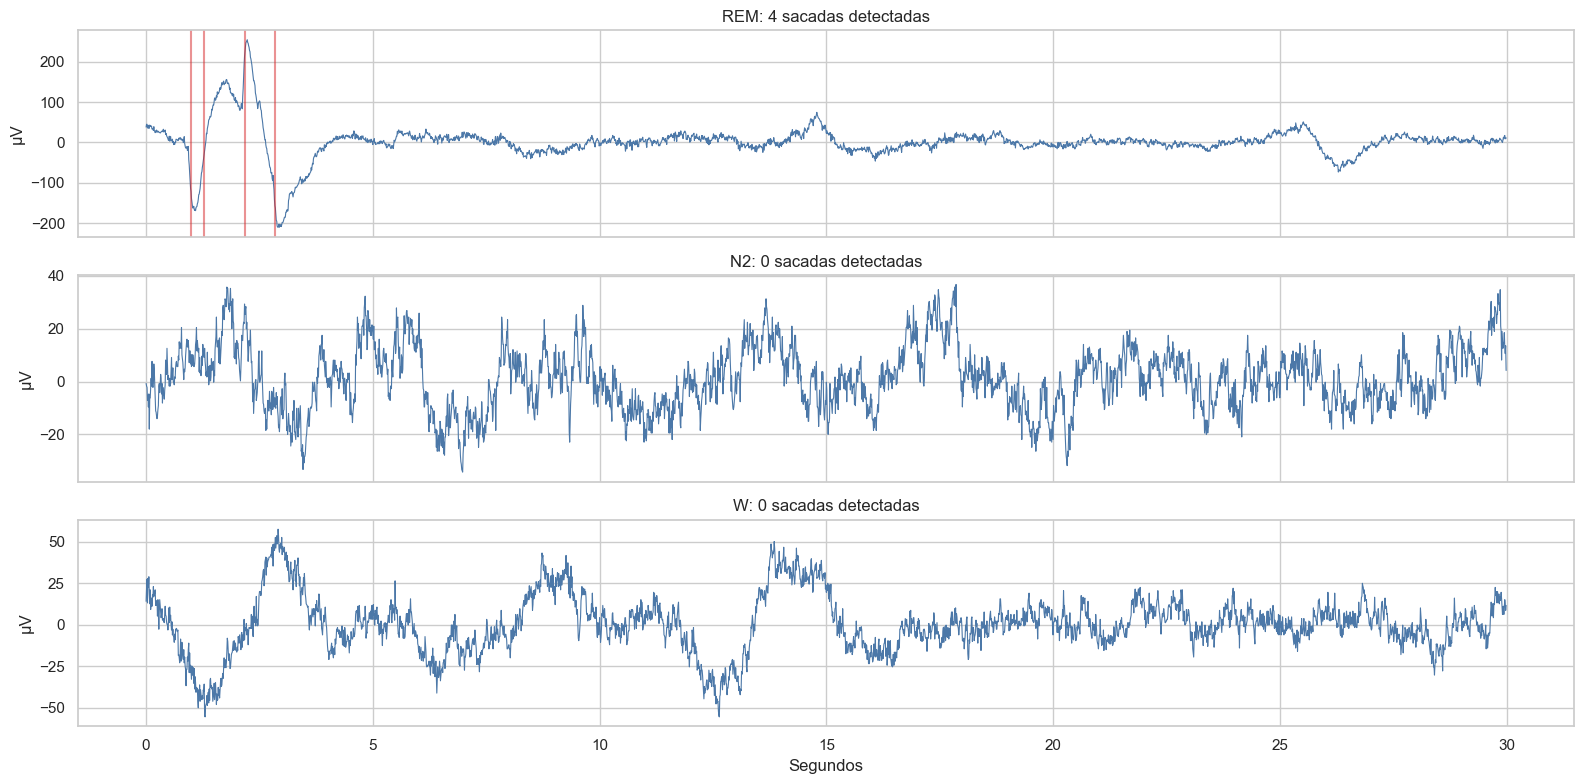

In [5]:
# Ejemplo visual: una época de REM con las sacadas detectadas marcadas
example_path = next(p for p in pairs if Path(p[0]).name.startswith("SC4001"))
raw = load_psg(example_path[0], canales=[EOG_CHANNEL])
annotations = load_hypnogram(example_path[1])
raw.set_annotations(annotations, emit_warning=False)
example = trim_wake_edges(
    extract_epochs(raw, annotations, recording_id="SC4001E0", channel_picks=[EOG_CHANNEL]),
    buffer_epochs=TRIM_WAKE_BUFFER_EPOCHS,
)

fig, axes = plt.subplots(3, 1, figsize=(16, 8), sharex=True)
for ax, stage in zip(axes, ["REM", "N2", "W"]):
    idx = np.flatnonzero(example.y == stage)[len(np.flatnonzero(example.y == stage)) // 2]
    signal = example.X[idx, 0, :]
    t = np.arange(signal.size) / example.sfreq

    smooth_len = round(fe.SACCADE_SMOOTH_SEC * example.sfreq)
    smoothed = np.convolve(signal, np.ones(smooth_len) / smooth_len, mode="valid")
    velocity = np.abs(np.diff(smoothed)) * example.sfreq
    peaks, _ = find_peaks(velocity, height=fe.SACCADE_VELOCITY_UV_S,
                          distance=round(fe.SACCADE_MIN_INTERVAL_SEC * example.sfreq))
    peak_times = (peaks + smooth_len / 2) / example.sfreq

    ax.plot(t, signal, color="#4C78A8", linewidth=0.8)
    for pt in peak_times:
        ax.axvline(pt, color="tab:red", alpha=0.5)
    ax.set_title(f"{stage}: {len(peaks)} sacadas detectadas")
    ax.set_ylabel("µV")
axes[-1].set_xlabel("Segundos")
plt.tight_layout()
plt.show()

### Conclusión de la calibración

Se eligió un umbral de **750 µV/s con 100 ms de suavizado** porque logra un AUC casi máximo sin contar como sacadas las ondas lentas de N3.

- **Con 100 ms de suavizado, 750 µV/s es el máximo de la curva** (AUC 0,690, frente a 0,641 con 500 µV/s y 0,671 con 1000 µV/s). Con umbrales más altos se pierden sacadas reales y el AUC baja hasta 0,518 con 3000 µV/s.
- **Con 50 ms de suavizado queda demasiado ruido**: con 750 µV/s se cuentan 11,2 sacadas por época en N3, más que en REM (9,9), y el mejor AUC de esa curva es solo 0,654.
- **La combinación de 500 µV/s con 150 ms tiene el AUC más alto (0,699), pero cuenta 3,3 sacadas por época en N3**, casi tantas como en REM (4,6). En N3 no hay movimientos oculares rápidos, así que con un umbral bajo y mucho suavizado el detector está contando ondas lentas de alta amplitud. Con 750 µV/s y 100 ms, REM tiene el doble de sacadas que N3 (3,3 frente a 1,6).
- **La combinación de 750 µV/s con 150 ms cuenta menos en N3 (0,5), pero baja el AUC a 0,680** y detecta menos sacadas en REM (2,2 por época).

La configuración elegida queda en el punto intermedio entre separar REM de N1 + N2 y no confundirse con N3. Las tres mejores configuraciones difieren en menos de 0,02 de AUC, así que la elección se apoya más en el comportamiento en N3 que en la diferencia de AUC. Todo se calculó solo con sujetos de train.

## 3. Validación por clase y redundancia (solo train)

`saccade_count` se toma con el umbral y el suavizado fijados en `feature_engineering.py`. Comportamiento esperado:

| Feature | Esperado |
|---|---|
| `p2p_robust` | Mayor en **W** y **REM** |
| `hjorth_mobility` | Distinta entre REM y N1 |
| `saccade_count` | Mayor en **REM** que en N1, N2 y N3 |
| `kurtosis` | Mayor en **W** y **REM** |

y,W,N1,N2,N3,REM
spec__beta_power_abs,19.064,4.208,3.068,3.134,3.257
spec__delta_power_abs,1066.868,90.381,72.780,275.776,204.700
spec__delta_power_rel,0.901,0.801,0.783,0.907,0.925
p2p_robust,271.866,85.129,61.960,100.948,142.199
hjorth_mobility,28.090,34.058,36.632,23.705,19.531
saccade_count,16.000,0.000,0.000,0.000,1.000
kurtosis,1.305,0.677,0.740,0.410,2.590


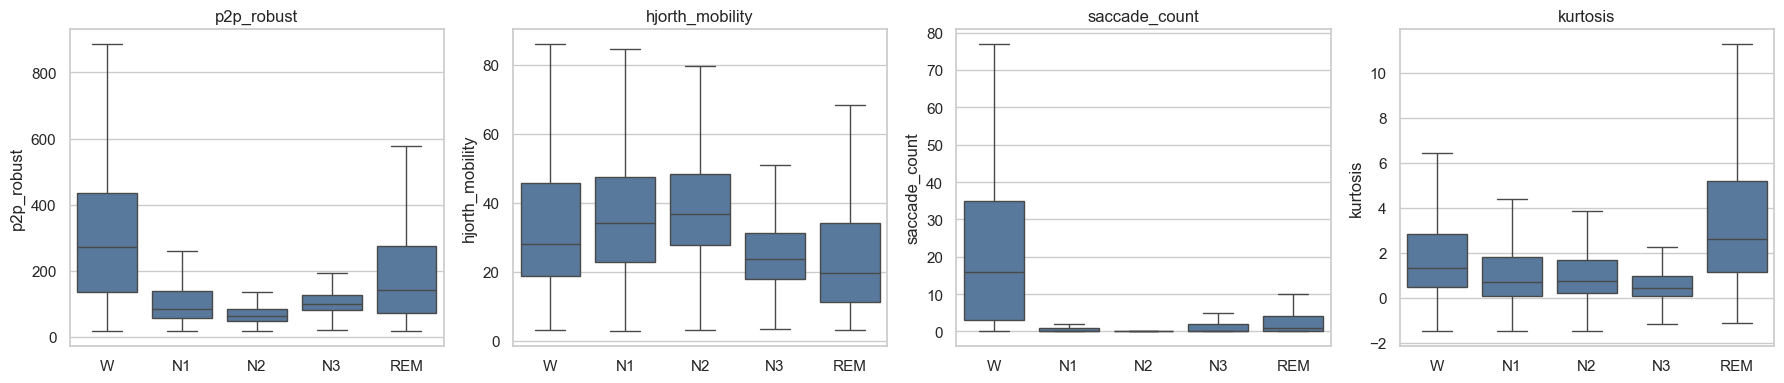

In [6]:
selected_saccade_col = f"sacc_t{int(fe.SACCADE_VELOCITY_UV_S)}_s{int(fe.SACCADE_SMOOTH_SEC * 1000)}"
eog_df["saccade_count"] = eog_df[selected_saccade_col]
eog_train = eog_df[eog_df["split"] == "train"]

NEW_FEATURES = ["p2p_robust", "hjorth_mobility", "saccade_count", "kurtosis"]
KEPT_SPECTRAL = ["spec__beta_power_abs", "spec__delta_power_abs", "spec__delta_power_rel"]
VALIDATION_FEATURES = KEPT_SPECTRAL + NEW_FEATURES

display(eog_train.groupby("y")[VALIDATION_FEATURES].median().reindex(CLASS_ORDER).T.round(3))

fig, axes = plt.subplots(1, len(NEW_FEATURES), figsize=(18, 4))
for ax, feature in zip(axes, NEW_FEATURES):
    sns.boxplot(data=eog_train, x="y", y=feature, order=CLASS_ORDER, showfliers=False, ax=ax, color="#4C78A8")
    ax.set_title(feature)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [7]:
# AUC uno contra el resto: > 0.5 la feature es mayor en esa clase, < 0.5 es menor
auc_rows = []
for feature in VALIDATION_FEATURES:
    values = eog_train[feature].fillna(eog_train[feature].median())
    row = {"feature": feature}
    for stage in CLASS_ORDER:
        row[stage] = roc_auc_score(eog_train["y"] == stage, values)
    row["kruskal_H"] = kruskal(*[eog_train.loc[eog_train["y"] == s, feature].dropna() for s in CLASS_ORDER]).statistic
    auc_rows.append(row)
display(pd.DataFrame(auc_rows).round(3))

,feature,W,N1,N2,N3,REM,kruskal_H
0,spec__beta_power_abs,0.919,0.462,0.241,0.321,0.346,72814.763
1,spec__delta_power_abs,0.829,0.361,0.205,0.610,0.511,56344.746
2,spec__delta_power_rel,0.625,0.402,0.275,0.684,0.685,29087.112
3,p2p_robust,0.839,0.415,0.174,0.501,0.570,61066.684
4,hjorth_mobility,0.473,0.543,0.647,0.357,0.305,15307.681
5,saccade_count,0.857,0.366,0.235,0.425,0.499,65582.517
6,kurtosis,0.572,0.419,0.405,0.326,0.717,16642.551


In [8]:
spectral_cols = [col for col in eog_df.columns if col.startswith("spec__")]
spearman = eog_train[spectral_cols + NEW_FEATURES].corr(method="spearman")

redundancy = []
for feature in NEW_FEATURES:
    others = spearman.loc[feature].drop(feature).abs().sort_values(ascending=False)
    redundancy.append({"feature": feature, "más_correlacionada": others.index[0], "abs_spearman": others.iloc[0]})
display(pd.DataFrame(redundancy).round(3))

,feature,más_correlacionada,abs_spearman
0,p2p_robust,spec__delta_power_abs,0.957
1,hjorth_mobility,spec__sef95,0.899
2,saccade_count,p2p_robust,0.822
3,kurtosis,saccade_count,0.302
